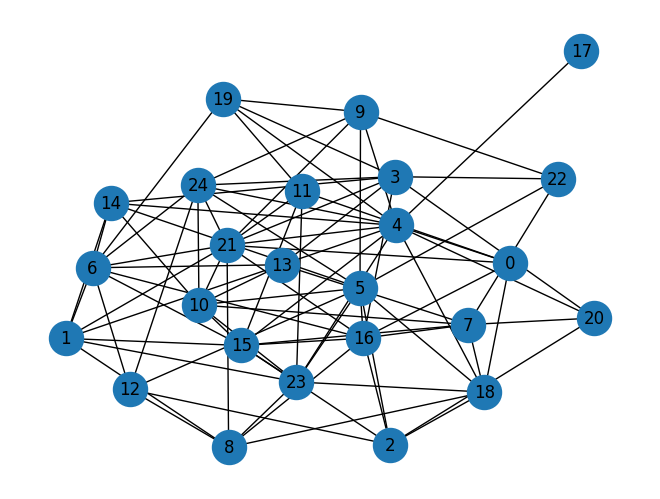

In [19]:
import numpy as np
import rustworkx as rx

def planted_maxcut_adjacency_matrix(n, p_between=0.5, p_within=0.1, seed=None):
    if seed is not None:
        np.random.seed(seed)

    adj_matrix = np.zeros((n, n))
    half = n // 2
    set_A = range(half)
    set_B = range(half, n)

    # Edges between the partitions (cut edges)
    for i in set_A:
        for j in set_B:
            if np.random.rand() < p_between:
                adj_matrix[i, j] = 1.0
                adj_matrix[j, i] = 1.0

    # Edges within the partitions (non-cut edges)
    for part in [set_A, set_B]:
        for i in part:
            for j in part:
                if i < j and np.random.rand() < p_within:
                    adj_matrix[i, j] = 1.0
                    adj_matrix[j, i] = 1.0

    planted_cut = [0 if i in set_A else 1 for i in range(n)]

    return adj_matrix, planted_cut

# Parameters
n = 25
adj_matrix, planted_cut = planted_maxcut_adjacency_matrix(n, seed=0)

# Create the rustworkx graph
graph = rx.PyGraph.from_adjacency_matrix(adj_matrix)

# Draw (optional)
from rustworkx.visualization import mpl_draw
mpl_draw(graph, node_size=600, with_labels=True)

In [20]:
from qiskit.quantum_info import SparsePauliOp
def build_max_cut_paulis(graph: rx.PyGraph) -> list[tuple[str, float]]:
    """Convert the graph to Pauli list.

    This function does the inverse of `build_max_cut_graph`
    """
    pauli_list = []
    for edge in list(graph.edge_list()):
        paulis = ["I"] * len(graph)
        paulis[edge[0]], paulis[edge[1]] = "Z", "Z"

        weight = graph.get_edge_data(edge[0], edge[1])

        pauli_list.append(("".join(paulis)[::-1], weight))

    return pauli_list


max_cut_paulis = build_max_cut_paulis(graph)

cost_hamiltonian = SparsePauliOp.from_list(max_cut_paulis)
print("Cost Function Hamiltonian:", cost_hamiltonian)

Cost Function Hamiltonian: SparsePauliOp(['IIIIIIIIIIIIIIIIIIIIZIIIZ', 'IIIIIIIIIIIIIZIIIIIIIIIIZ', 'IIIIIIIIZIIIIIIIIIIIIIIIZ', 'IIIIIIZIIIIIIIIIIIIIIIIIZ', 'IIIZIIIIIIIIIIIIIIIIIIIIZ', 'IIIIIIIIIIIIIIIIIIZIIIIZI', 'IIIIIIIIIIIIIIIIZIIIIIIZI', 'IIIIIIIIIIIZIIIIIIIIIIIZI', 'IIIIIIIIIIZIIIIIIIIIIIIZI', 'IIIIIIIIIZIIIIIIIIIIIIIZI', 'IIIZIIIIIIIIIIIIIIIIIIIZI', 'IZIIIIIIIIIIIIIIIIIIIIIZI', 'IIIIIIIIIIIIIIIIIIIZIIZII', 'IIIIIIIIIIIIZIIIIIIIIIZII', 'IIIIIIIIIZIIIIIIIIIIIIZII', 'IIIIIIIIZIIIIIIIIIIIIIZII', 'IIIIIIZIIIIIIIIIIIIIIIZII', 'IIIIZIIIIIIIIIIIIIIIIIZII', 'IIIIIIIIIIIZIIIIIIIIIZIII', 'IIIIIIIIIIZIIIIIIIIIIZIII', 'IIIIIIIIZIIIIIIIIIIIIZIII', 'IIIIIZIIIIIIIIIIIIIIIZIII', 'IIIIZIIIIIIIIIIIIIIIIZIII', 'IIIZIIIIIIIIIIIIIIIIIZIII', 'IIZIIIIIIIIIIIIIIIIIIZIII', 'ZIIIIIIIIIIIIIIIIIIIIZIII', 'IIIIIIIIIIIIIIIZIIIIZIIII', 'IIIIIIIIIIIZIIIIIIIIZIIII', 'IIIIIIIIIIZIIIIIIIIIZIIII', 'IIIIIIIIIZIIIIIIIIIIZIIII', 'IIIIIIIZIIIIIIIIIIIIZIIII', 'IIIIIIZIIIIIIIIIIIIIZIIII', 'IIIIIZIIIIIIIIIIIIIIZIIII', '

In [21]:
import numpy as np
from scipy.sparse.csgraph import laplacian
from scipy.linalg import eigh

L = laplacian(adj_matrix, normed=True)
# L = laplacian(adj_matrix)

# Compute eigenvectors
vals, vecs = eigh(L)

# Fiedler vector (2nd smallest eigenvalue)
fiedler = vecs[:,1]
print(fiedler)

[-0.16494642 -0.16995901 -0.19896454  0.34457272  0.13709249  0.02667647
  0.03842463  0.02112307 -0.33279226  0.36288788  0.01029034 -0.1256458
 -0.11460418  0.10881307  0.10921763 -0.21380099 -0.15063402  0.08675123
 -0.28136669  0.26092779  0.09662262  0.01630262  0.31389523 -0.29625183
  0.2232755 ]


In [22]:
sorted_nodes = np.argsort(fiedler)
sorted_nodes

array([ 8, 23, 18, 15,  2,  1,  0, 16, 11, 12, 10, 21,  7,  5,  6, 17, 20,
       13, 14,  4, 24, 19, 22,  3,  9])

In [23]:
from qiskit.circuit.library import QAOAAnsatz

reps=3
circuit = QAOAAnsatz(cost_operator=cost_hamiltonian, reps=reps)
circuit.measure_all()

# circuit.draw('mpl')

Initialize Params

In [24]:
initial_gamma = np.pi
initial_beta = np.pi/2
init_params = [initial_gamma, initial_beta] * reps

In [25]:
objective_func_vals = [] # Global variable

def cost_func_estimator(params, ansatz, hamiltonian, estimator):
    isa_hamiltonian = hamiltonian.apply_layout(ansatz.layout)

    pub = (ansatz, isa_hamiltonian, params)
    job = estimator.run([pub])

    results = job.result()[0]
    cost = results.data.evs

    objective_func_vals.append(cost)

    return cost

In [26]:
from qiskit_ibm_runtime import QiskitRuntimeService

# QiskitRuntimeService.save_account(channel="ibm_quantum", token="<MY_IBM_QUANTUM_TOKEN>", overwrite=True, set_as_default=True)
service = QiskitRuntimeService(channel='ibm_quantum', token='205d1b23f51dba2efe445b1b44f1e07939499dba4f4343c67d9004c25b833489b950240921dc782935c419c08569dbc6d642584e5835a97fde387586b542d8ac')
backend = service.backend('ibm_brisbane')

C:\Users\devra\AppData\Local\Temp\ipykernel_12476\4199271211.py:4: DeprecationWarning: The "ibm_quantum" channel option is deprecated and will be sunset on 1 July. After this date, "ibm_cloud" and "local" will be the only valid channels. For information on migrating to the new IBM Quantum Platform on the "ibm_cloud" channel, review the migration guide https://quantum.cloud.ibm.com/docs/migration-guides/classic-iqp-to-cloud-iqp .
  service = QiskitRuntimeService(channel='ibm_quantum', token='205d1b23f51dba2efe445b1b44f1e07939499dba4f4343c67d9004c25b833489b950240921dc782935c419c08569dbc6d642584e5835a97fde387586b542d8ac')


In [27]:
basis_gates = backend.basis_gates
basis_gates

['ecr', 'id', 'rz', 'sx', 'x']

In [28]:
# from qiskit import transpile
# from qiskit.visualization import plot_coupling_map

# num_qubits = backend.configuration().num_qubits
# grid_size = int(num_qubits ** 0.5) + 1
# grid_size = int(num_qubits ** 0.5) + 1
# qubit_coordinates = [(i % grid_size, i // grid_size) for i in range(num_qubits)]

# # Plot the coupling map
# plot_coupling_map(coupling_map=backend.configuration().coupling_map,
#                   num_qubits=backend.configuration().num_qubits,
#                   qubit_coordinates=qubit_coordinates)


In [29]:
coupling_map = backend.coupling_map

# Get adjacency as a dict: {qubit: [connected_qubits]}
adj = {i: [] for i in range(backend.configuration().num_qubits)}
for (i, j) in coupling_map:
    adj[i].append(j)
    adj[j].append(i)

# Greedy DFS to build a chain
def find_linear_chain(adj, length):
    for start in adj:
        path = [start]
        visited = {start}
        while len(path) < length:
            last = path[-1]
            next_nodes = [n for n in adj[last] if n not in visited]
            if not next_nodes:
                break
            next_node = next_nodes[0]
            path.append(next_node)
            visited.add(next_node)
        if len(path) == length:
            return path
    return None

chain = find_linear_chain(adj, n)  # Length = number of qubits = nodes
chain

[7,
 6,
 5,
 4,
 3,
 2,
 1,
 0,
 14,
 18,
 19,
 20,
 33,
 39,
 38,
 37,
 52,
 56,
 57,
 58,
 59,
 60,
 53,
 41,
 40]

In [30]:
sorted_nodes

array([ 8, 23, 18, 15,  2,  1,  0, 16, 11, 12, 10, 21,  7,  5,  6, 17, 20,
       13, 14,  4, 24, 19, 22,  3,  9])

In [31]:
# sorted_indices[i] is the logical qubit index (graph node)
# chain[i] is the physical qubit index
logical_to_physical = {sorted_nodes[i]: chain[i] for i in range(n)}
logical_to_physical

{np.int64(8): 7,
 np.int64(23): 6,
 np.int64(18): 5,
 np.int64(15): 4,
 np.int64(2): 3,
 np.int64(1): 2,
 np.int64(0): 1,
 np.int64(16): 0,
 np.int64(11): 14,
 np.int64(12): 18,
 np.int64(10): 19,
 np.int64(21): 20,
 np.int64(7): 33,
 np.int64(5): 39,
 np.int64(6): 38,
 np.int64(17): 37,
 np.int64(20): 52,
 np.int64(13): 56,
 np.int64(14): 57,
 np.int64(4): 58,
 np.int64(24): 59,
 np.int64(19): 60,
 np.int64(22): 53,
 np.int64(3): 41,
 np.int64(9): 40}

In [32]:
from qiskit.transpiler import Layout

initial_layout = Layout({q: logical_to_physical[i] for i,q in enumerate(circuit.qubits)})
initial_layout

Layout({
1: <Qubit register=(25, "q"), index=0>,
2: <Qubit register=(25, "q"), index=1>,
3: <Qubit register=(25, "q"), index=2>,
41: <Qubit register=(25, "q"), index=3>,
58: <Qubit register=(25, "q"), index=4>,
39: <Qubit register=(25, "q"), index=5>,
38: <Qubit register=(25, "q"), index=6>,
33: <Qubit register=(25, "q"), index=7>,
7: <Qubit register=(25, "q"), index=8>,
40: <Qubit register=(25, "q"), index=9>,
19: <Qubit register=(25, "q"), index=10>,
14: <Qubit register=(25, "q"), index=11>,
18: <Qubit register=(25, "q"), index=12>,
56: <Qubit register=(25, "q"), index=13>,
57: <Qubit register=(25, "q"), index=14>,
4: <Qubit register=(25, "q"), index=15>,
0: <Qubit register=(25, "q"), index=16>,
37: <Qubit register=(25, "q"), index=17>,
5: <Qubit register=(25, "q"), index=18>,
60: <Qubit register=(25, "q"), index=19>,
52: <Qubit register=(25, "q"), index=20>,
20: <Qubit register=(25, "q"), index=21>,
53: <Qubit register=(25, "q"), index=22>,
6: <Qubit register=(25, "q"), index=23>,
5

In [33]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit import transpile

basis_change = transpile(circuit, basis_gates=basis_gates, seed_transpiler=0)
# basis_change.draw('mpl', fold=False)

In [34]:
from qiskit.transpiler import PassManager, CouplingMap, Layout
from qiskit.transpiler.passes import (
    SetLayout,
    EnlargeWithAncilla,
    FullAncillaAllocation,
    ApplyLayout,
    SabreSwap
)

coupling_map = CouplingMap(backend.configuration().coupling_map)

# Create custom PassManager to stop at SabreSwap
pm = PassManager([
    SetLayout(initial_layout),
    EnlargeWithAncilla(),
    FullAncillaAllocation(coupling_map),
    ApplyLayout(),
    SabreSwap(coupling_map, heuristic='basic', seed=0)
])

# Transpile using the custom pipeline
transpiled = pm.run(basis_change)

# View the circuit with SWAP gates intact
# print(transpiled)
print("SWAP gates inserted:", transpiled.count_ops().get("swap", 0))

SWAP gates inserted: 853


In [36]:
import rustworkx as rx
import numpy as np
from rustworkx.visualization import mpl_draw as draw_graph
import networkx as nx
from qiskit.quantum_info import SparsePauliOp
import numpy as np
from scipy.sparse.csgraph import laplacian
from scipy.linalg import eigh
from qiskit.circuit.library import QAOAAnsatz
from qiskit.transpiler import Layout
from qiskit import transpile
from qiskit.transpiler import PassManager, CouplingMap, Layout
from qiskit.transpiler.passes import (
    SetLayout,
    EnlargeWithAncilla,
    FullAncillaAllocation,
    ApplyLayout,
    SabreSwap,
    SabreLayout
)

def count_swaps_in_QAOA_circuit(graph: rx.PyGraph, backend, reps=2, start='warm'):
    def build_max_cut_paulis(graph: rx.PyGraph) -> list[tuple[str, float]]:
        """Convert the graph to Pauli list.

        This function does the inverse of `build_max_cut_graph`
        """
        pauli_list = []
        for edge in list(graph.edge_list()):
            paulis = ["I"] * len(graph)
            paulis[edge[0]], paulis[edge[1]] = "Z", "Z"

            weight = graph.get_edge_data(edge[0], edge[1])

            pauli_list.append(("".join(paulis)[::-1], weight))

        return pauli_list
    
    max_cut_paulis = build_max_cut_paulis(graph)
    cost_hamiltonian = SparsePauliOp.from_list(max_cut_paulis)

    L = laplacian(adj_matrix)
    vals, vecs = eigh(L)
    fiedler = vecs[:,1]

    if start=='warm':
        sorted_nodes = np.argsort(fiedler)

    circuit = QAOAAnsatz(cost_operator=cost_hamiltonian, reps=reps)
    circuit.measure_all()

    basis_gates = backend.basis_gates
    coupling_map = backend.coupling_map

    # Get adjacency as a dict: {qubit: [connected_qubits]}
    adj = {i: [] for i in range(backend.configuration().num_qubits)}
    for (i, j) in coupling_map:
        adj[i].append(j)
        adj[j].append(i)

    # Greedy DFS to build a chain
    def find_linear_chain(adj, length):
        for start in adj:
            path = [start]
            visited = {start}
            while len(path) < length:
                last = path[-1]
                next_nodes = [n for n in adj[last] if n not in visited]
                if not next_nodes:
                    break
                next_node = next_nodes[0]
                path.append(next_node)
                visited.add(next_node)
            if len(path) == length:
                return path
        return None

    chain = find_linear_chain(adj, n)  # Length = number of qubits = nodes
    if not chain:
        return -1
    
    if start=='warm':
        logical_to_physical = {sorted_nodes[i]: chain[i] for i in range(n)}
    else:
        logical_to_physical = {i: chain[i] for i in range(n)}

    initial_layout = Layout({q: logical_to_physical[i] for i,q in enumerate(circuit.qubits)})

    basis_change = transpile(circuit, basis_gates=basis_gates, seed_transpiler=0)

    pm = PassManager([
        SetLayout(initial_layout),
        EnlargeWithAncilla(),
        FullAncillaAllocation(coupling_map),
        ApplyLayout(),
        SabreSwap(coupling_map, heuristic='basic', seed=0)
    ])

    # Transpile using the custom pipeline
    transpiled = pm.run(basis_change)
    return transpiled.count_ops().get("swap", 0)
